# Part 3: Ranking & Filtering

## Exercise 2. Word2Vec + Cosine Similarity

We reuse the preprocessing pipeline and conjunctive retrieval (AND) from Parts 1 and 2.
For each of the **five queries selected in Part 2**, we rank matching products using Word2Vec embeddings and cosine similarity. We return the **top 20** results for each query.

## 1. Data Loading and Preprocessing

We reuse the same `df_processed` and `preprocess_text()` from Part 1, so documents and queries follow exactly the same normalization steps as in Lab 2.

The notebook can be placed in the **same directory as Part 2**. As in your Lab 2, it first looks for Part 1 in `../Part1/`. It also checks the current directory.

   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
    --------------------------------------- 0.5/24.4 MB 5.7 MB/s eta 0:00:05
    --------------------------------------- 0.5/24.4 MB 5.7 MB/s eta 0:00:05
   ---- ----------------------------------- 2.6/24.4 MB 4.3 MB/s eta 0:00:06
   ---------- ----------------------------- 6.3/24.4 MB 7.7 MB/s eta 0:00:03
   ------------------ --------------------- 11.0/24.4 MB 10.7 MB/s eta 0:00:02
   ------------------------ --------------- 14.9/24.4 MB 12.1 MB/s eta 0:00:01
   ---------------------------------- ----- 21.0/24.4 MB 14.6 MB/s eta 0:00:01
   ---------------------------------------- 24.4/24.4 MB 15.2 MB/s  0:00:01
Note: you may need to restart the kernel to use updated packages.
Loading Part 1: ..\Part1\Text_Processing_and_Exploratory_Data_Analysis_IRWA.ipynb


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\FA507\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\FA507\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\FA507\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\FA507\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Dataset principal: (28080, 17)
Validation labels: (40, 4)
DATA VALIDATION SUMMARY

Dataset shape:
(28080, 17)

Missing values per column:
_id                0
actual_price       0
average_rating     0
brand              0
category           0
crawled_at         0
description        0
discount           0
images             0
out_of_stock       0
pid                0
product_details    0
seller             0
selling_price      0
sub_category       0
title              0
url                0
dtype: int64

Empty strings in important text fields:
title: 0
description: 11150
brand: 2009
category: 0
sub_category: 0
seller: 1643

Duplicate PID values:
0

Unique PID values:
28080

out_of_stock values:
out_of_stock
False    26436
True      1644
Name: count, dtype: int64

Numeric fields summary:


,selling_price,actual_price,average_rating
count,28080,28080,28080
unique,1512,728,39
top,399,999,3.9
freq,1500,3504,2605


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\FA507\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


['title', 'pid', 'query_id', 'labels']


... (2 outputs left out)

,query_id,query,title,title_processed,description_processed,brand_processed,sub_category_processed,product_details_processed
0,1,women full sleeve sweatshirt cotton,Full Sleeve Printed Women Sweatshirt,"[full, sleev, print, women, sweatshirt]","[hoodi, women, stylish, made, 100, premium, co...",[cupidsto],"[winter, wear]","[color, dark, blue, fabric, cotton, blend, pat..."
2,1,women full sleeve sweatshirt cotton,Full Sleeve Printed Women Sweatshirt,"[full, sleev, print, women, sweatshirt]","[product, stori, live, larg, big, logo, women,...",[pu],"[winter, wear]","[color, red, fabric, cotton, blend, pattern, p..."
3,1,women full sleeve sweatshirt cotton,Full Sleeve Graphic Print Women Sweatshirt,"[full, sleev, graphic, print, women, sweatshirt]","[free, author, present, print, sweatshirt, fea...","[free, authori]","[winter, wear]","[color, yellow, fabric, polycotton, pattern, g..."
5,1,women full sleeve sweatshirt cotton,Full Sleeve Graphic Print Women Sweatshirt,"[full, sleev, graphic, print, women, sweatshirt]","[free, author, present, crew, neck, terri, swe...","[free, authori]","[winter, wear]","[color, red, fabric, polycotton, pattern, grap..."
7,1,women full sleeve sweatshirt cotton,Full Sleeve Printed Women Sweatshirt,"[full, sleev, print, women, sweatshirt]","[product, stori, celebr, global, connect, fash...",[pu],"[winter, wear]","[color, white, fabric, cotton, blend, pattern,..."
8,1,women full sleeve sweatshirt cotton,Full Sleeve Solid Women Sweatshirt,"[full, sleev, solid, women, sweatshirt]","[reebok, bomber, track, jacket, women, comfort...",[reeb],"[winter, wear]","[color, black, fabric, cotton, blend, pattern,..."
9,1,women full sleeve sweatshirt cotton,Full Sleeve Graphic Print Women Sweatshirt,"[full, sleev, graphic, print, women, sweatshirt]","[free, author, present, crew, neck, sweatshirt...","[free, authori]","[winter, wear]","[color, red, fabric, polycotton, pattern, grap..."
10,1,women full sleeve sweatshirt cotton,Full Sleeve Graphic Print Women Sweatshirt,"[full, sleev, graphic, print, women, sweatshirt]","[wear, nasa, logo, edit, women, cotton, sweats...","[tee, bud]","[winter, wear]","[color, grey, fabric, pure, cotton, pattern, g..."
14,1,women full sleeve sweatshirt cotton,Full Sleeve Color Block Women Sweatshirt,"[full, sleev, color, block, women, sweatshirt]","[freshen, winter, wardrob, sweatshirt, women, ...","[jack, har]","[winter, wear]","[color, multicolor, fabric, fleec, pattern, co..."
15,1,women full sleeve sweatshirt cotton,Full Sleeve Graphic Print Women Sweatshirt,"[full, sleev, graphic, print, women, sweatshirt]","[temperatur, dip, lower, time, invest, sweatsh...","[free, authori]","[winter, wear]","[color, maroon, fabric, pure, cotton, pattern,..."


title_processed_coverage  description_processed_coverage  \
query_id labels                                                             
1        0                          0.457                           0.629   
         1                          0.800                           0.585   
2        0                          0.725                           0.400   
         1                          0.800                           0.350   

                 brand_processed_coverage  category_processed_coverage  \
query_id labels                                                          
1        0                            0.0                          0.0   
         1                            0.0                          0.0   
2        0                            0.0                          0.0   
         1                            0.0                          0.0   

                 sub_category_processed_coverage  \
query_id labels                                    
1        0                                   0.0   
         1                                   0.0   
2        0                                   0.0   
         1                                   0.0   

                 product_details_processed_coverage  
query_id labels                                      
1        0                                    0.600  
         1                                    0.800  
2        0                                    0.475  
         1                                    0.650

VOCABULARY STATISTICS
Total tokens in titles: 176,056
Unique vocabulary size in titles: 728
Total tokens in descriptions: 528,498
Unique vocabulary size in descriptions: 4,697
Total unique vocabulary size across all search fields: 19,613

DOCUMENT LENGTH METRICS


,title_word_count,desc_word_count,desc_avg_sentence_length
count,28080.00,28080.00,28080.00
mean,6.27,18.82,11.25
std,1.98,26.69,14.78
min,1.00,0.00,0.00
25%,5.00,0.00,0.00
50%,6.00,9.00,9.33
75%,7.00,29.00,18.00
max,31.00,579.00,191.00


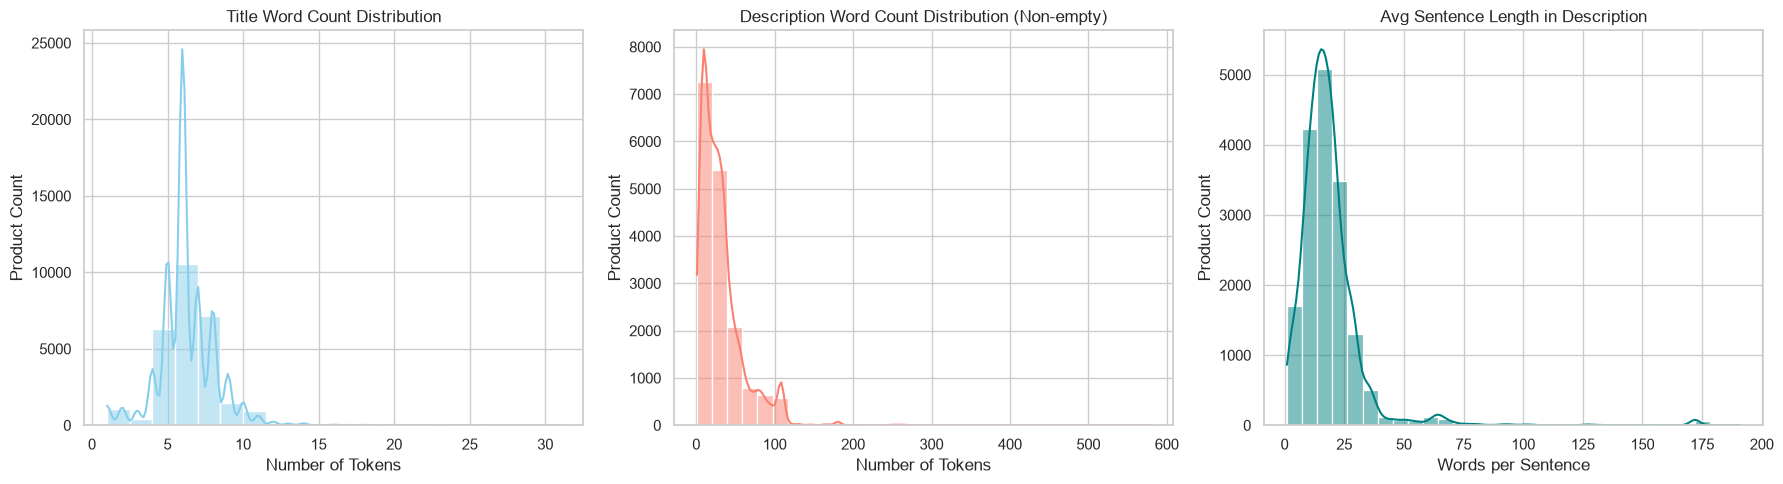

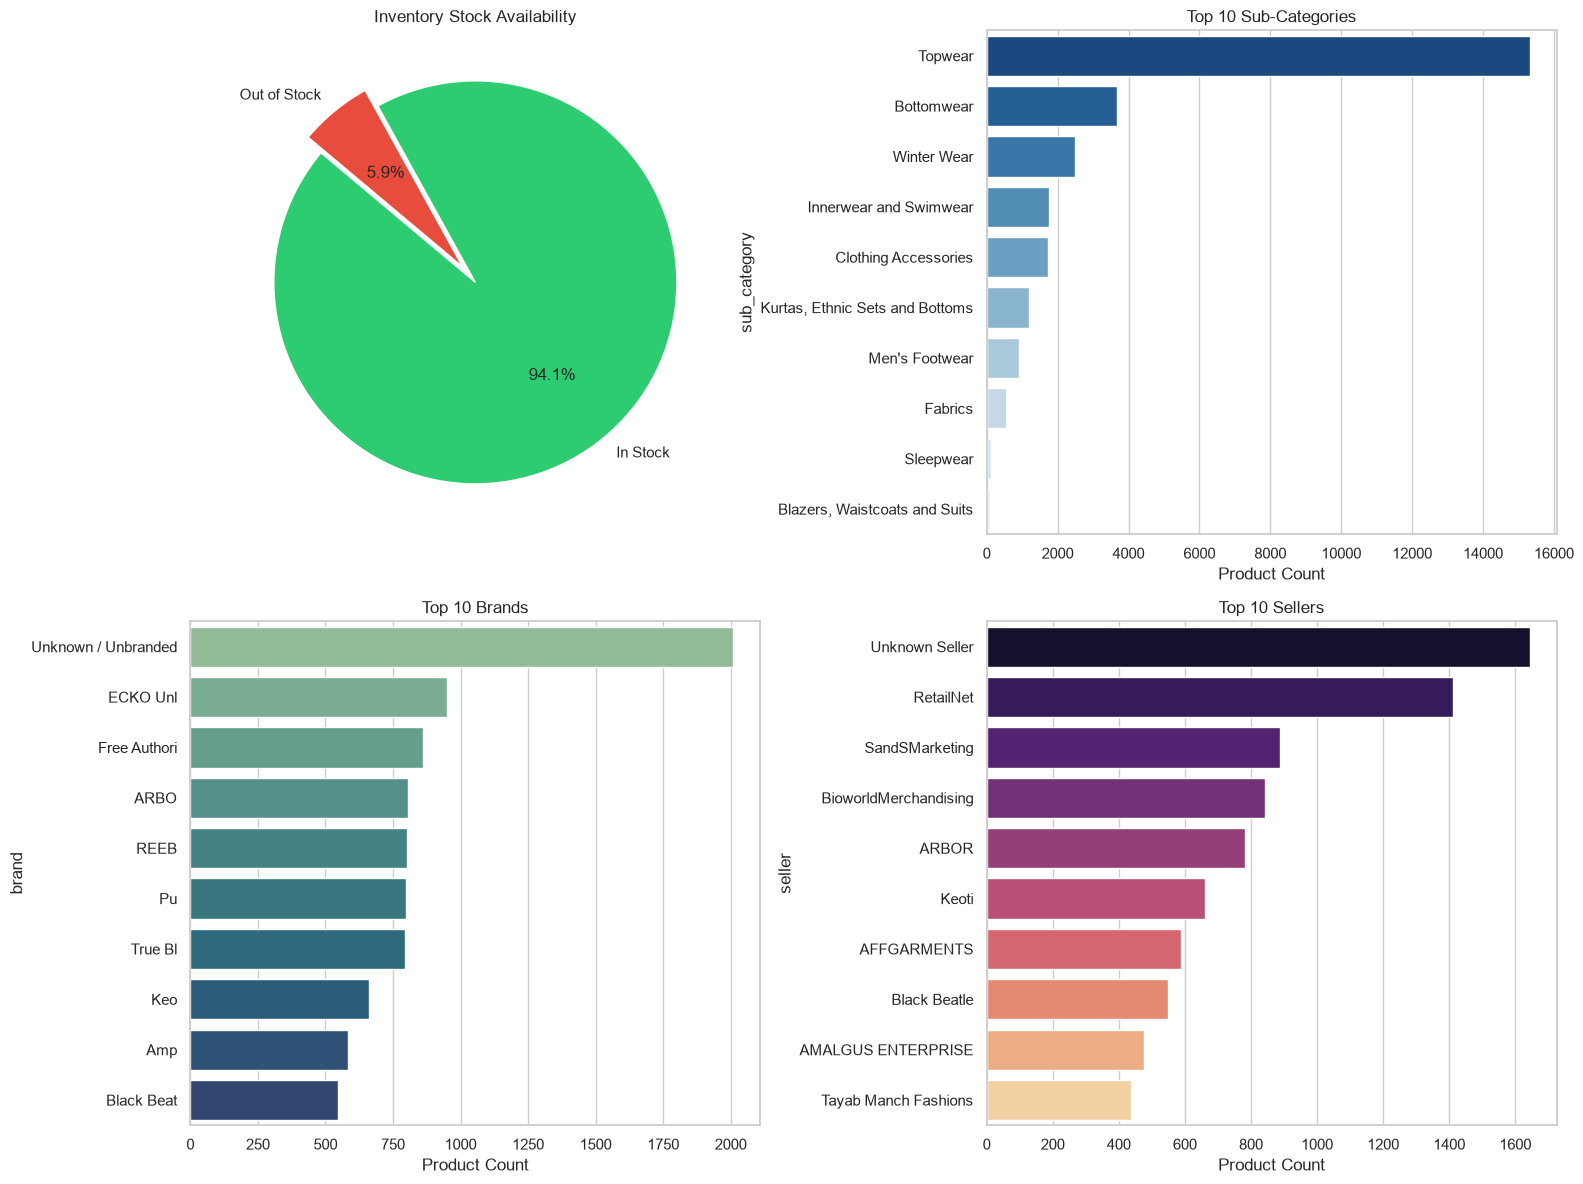

NUMERICAL ATTRIBUTES SUMMARY


,selling_price_numeric,actual_price_numeric,discount_numeric,average_rating_numeric
count,28078.00,27303.00,27225.00,25819.00
mean,705.64,1455.53,50.26,3.63
std,549.68,939.98,16.89,0.66
min,99.00,150.00,1.00,1.00
25%,390.00,849.00,40.00,3.20
50%,545.00,1199.00,53.00,3.80
75%,820.00,1799.00,63.00,4.10
max,7999.00,12999.00,87.00,5.00



TOP 5 HIGHEST RATED PRODUCTS


,pid,title,brand,average_rating_numeric,selling_price_numeric
13251,VESFSJ92YXMAJZFX,Sheny Women Vest,,5.0,184.0
9482,TSHFJHFFQHQBNVSV,Solid Women Round Neck Red T-Shirt,FancyW,5.0,215.0
4683,TSHFVUXHTE5KH7RH,Solid Men Polo Neck Dark Blue T-Shirt,Shoef,5.0,246.0
417,BXRFGYUGJCWWZ7UG,Printed Men Boxer (Pack of 1),SayItLo,5.0,249.0
443,BXRFKYKYF3SGUMFH,Printed Men Boxer (Pack of 1),SayItLo,5.0,249.0



TOP 5 HIGHEST DISCOUNTED PRODUCTS (%)


,pid,title,brand,actual_price_numeric,selling_price_numeric,discount_numeric
906,TSHF5FRXKGF6A4FH,Printed Women Round Neck White T-Shirt,Jack Roy,998.0,128.0,87.0
902,TSHFMFXGFJ7G2ABK,Printed Women Round Neck Grey T-Shirt,Jack Roy,999.0,136.0,86.0
903,TSHFMFT7VASAHBH3,Printed Women Round Neck White T-Shirt,Jack Roy,999.0,136.0,86.0
18249,TSHFGH6T3CVGDXS9,Printed Men Round Neck Multicolor T-Shirt (Pa...,yellowvib,2999.0,449.0,85.0
9813,CAPE9YWMURE4FKAJ,Solid Balclava Cap,Gracew,1499.0,228.0,84.0



TOP 5 MOST EXPENSIVE PRODUCTS


,pid,title,brand,selling_price_numeric,actual_price_numeric
2067,TKTFZ3YGGMMNBYEZ,Solid Women Track Suit,REEB,7999.0,9999.0
11010,BZRFVAX2QGTEGHRH,Checkered Single Breasted Party Women Full Sle...,True Bl,7998.0,7999.0
25815,JCKFQF5KMJJ349H8,Full Sleeve Solid Women Casual Jacket,Pu,7799.0,12999.0
26089,SWSFUMFGQFKVZGYH,Full Sleeve Printed Men Sweatshirt,Pu,7799.0,12999.0
6895,JEAF8S4GWU5YKQTF,Skinny Men Blue Jeans,G,7794.0,12990.0


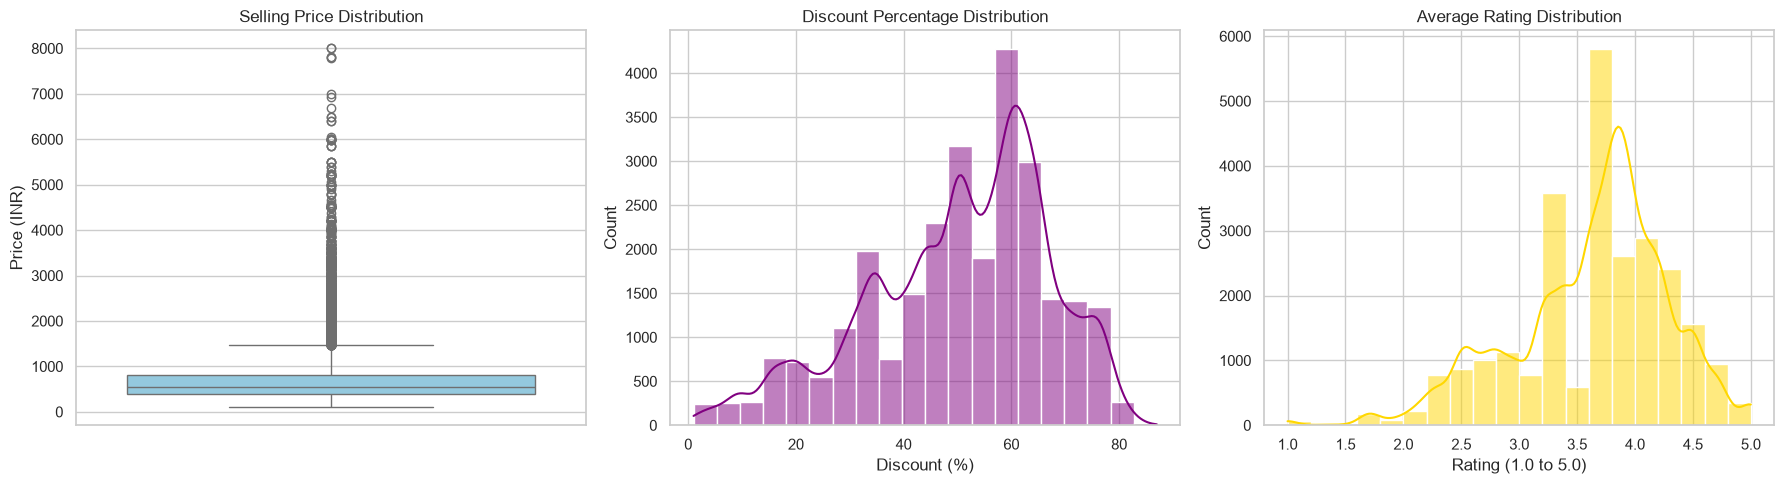

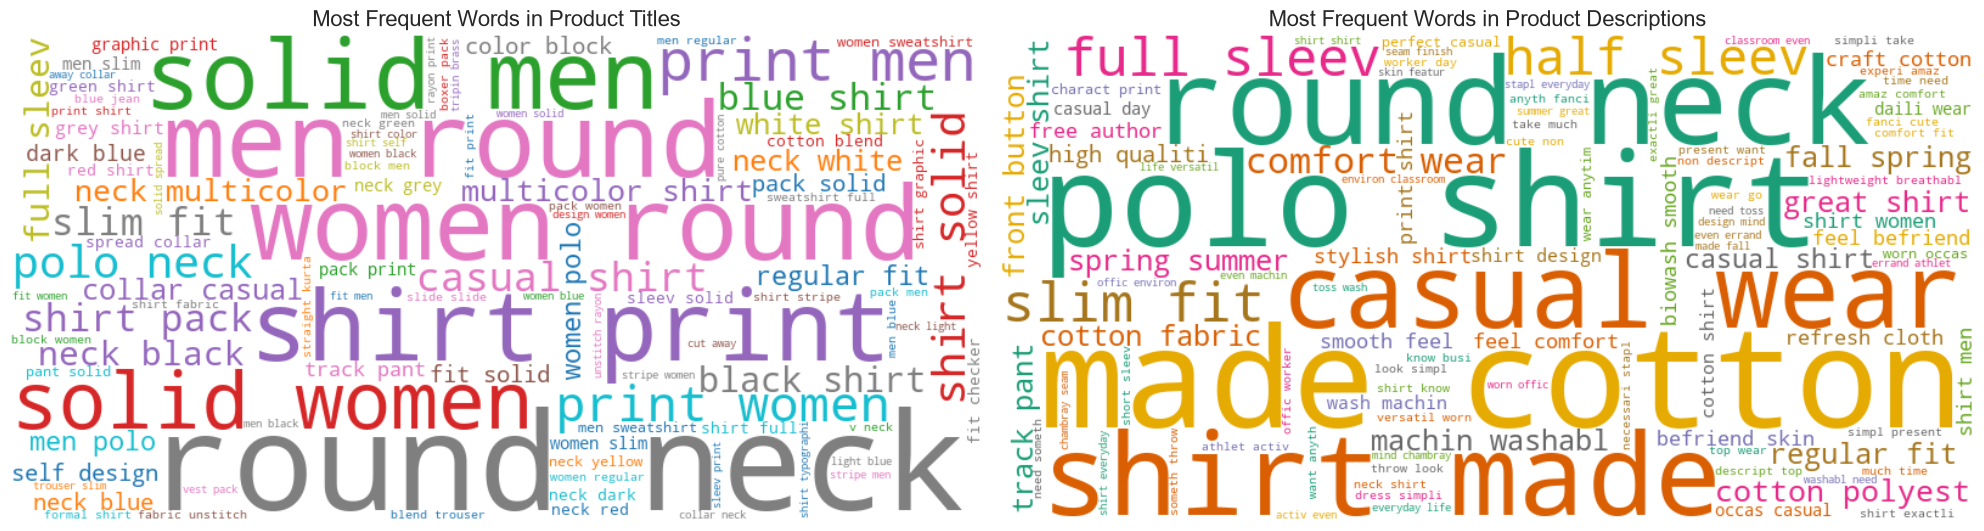

NAMED ENTITY RECOGNITION SUMMARY
Entity Label Counts:
Label
ORG            1382
PERSON          634
CARDINAL        558
GPE              38
WORK_OF_ART      22
FAC               4
PERCENT           3
DATE              3
QUANTITY          1
Name: count, dtype: int64

Top Entities per Category:
Label        Entity                                       
CARDINAL     2                                                220
             3                                                196
             4                                                 31
             6                                                 29
             1                                                 27
DATE         2021                                               1
             1307-9                                             1
             2010                                               1
FAC          Crew Black                                         2
             Tamil Nadu Parambariya                  

C:\Users\FA507\AppData\Local\Temp\ipykernel_29072\1709998728.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_entities, x="Label", order=df_entities["Label"].value_counts().index, palette="Set2")


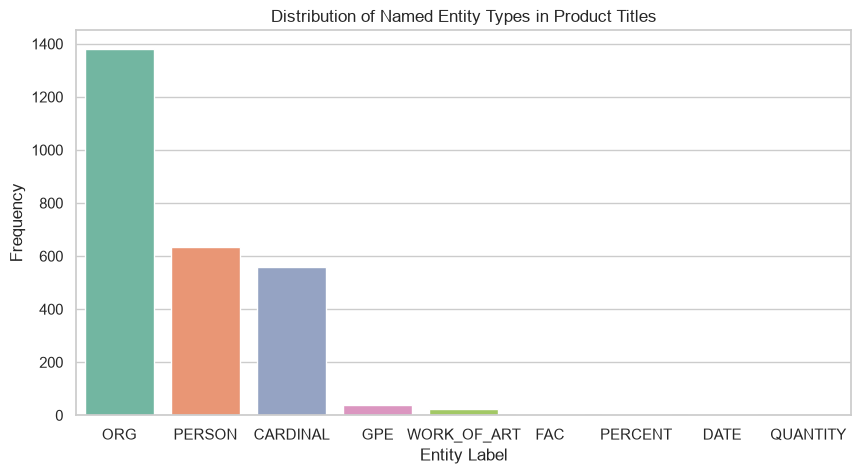

Total documents: 28080
Unique PIDs: 28080


,pid,title,search_tokens
0,TKPFCZ9EA7H5FYZH,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant, yorker..."
1,TKPFCZ9EJZV2UVRZ,Solid Men Blue Track Pants,"[solid, men, blue, track, pant, yorker, trackp..."
2,TKPFCZ9EHFCY5Z4Y,Solid Men Multicolor Track Pants,"[solid, men, multicolor, track, pant, yorker, ..."
3,TKPFCZ9ESZZ7YWEF,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant, yorker..."
4,TKPFCZ9EVXKBSUD7,"Solid Women Brown, Grey Track Pants","[solid, women, brown, grey, track, pant, yorke..."


In [1]:
# Install Word2Vec dependency once if needed:
%pip install gensim


import pandas as pd
import numpy as np
from pathlib import Path
from collections import defaultdict
from gensim.models import Word2Vec

# Part 1 notebook: same location used in Lab 2, with same-folder fallback
part1_candidates = [
    Path("../Part1/Text_Processing_and_Exploratory_Data_Analysis_IRWA.ipynb"),
    Path("Text_Processing_and_Exploratory_Data_Analysis_IRWA.ipynb"),
    Path("Part1/Text_Processing_and_Exploratory_Data_Analysis_IRWA.ipynb")
]
part1_path = next((p for p in part1_candidates if p.is_file()), None)

if part1_path is None:
    raise FileNotFoundError(
        "Part 1 notebook not found. Update part1_candidates with its relative path."
    )

print("Loading Part 1:", part1_path)
get_ipython().run_line_magic("run", f'"{part1_path}"')

# Verify the columns and preprocessing function used in Part 2
assert {"pid", "title", "search_tokens"}.issubset(df_processed.columns)
assert callable(preprocess_text)
print("Total documents:", len(df_processed))
print("Unique PIDs:", df_processed["pid"].nunique())
display(df_processed[["pid", "title", "search_tokens"]].head())

## 2. Inverted Index Construction

As in Part 2, each term is associated with the PIDs of the documents containing it. We build the same inverted index instead of running the entire Lab 2 (which would also execute its evaluation cells).

In [2]:
def build_inverted_index(df):
    inverted_index = defaultdict(set)

    for _, row in df.iterrows():
        pid = row["pid"]
        tokens = row["search_tokens"]

        for term in tokens:
            inverted_index[term].add(pid)

    return dict(inverted_index)


inverted_index = build_inverted_index(df_processed)
print("Number of indexed terms:", len(inverted_index))

Number of indexed terms: 19613


## 3. Conjunctive Query Processing (AND)

As required in Part 3, a product is considered for ranking **only if it contains all query terms**. We reuse the same `search_AND` logic from Part 2.

In [3]:
def search_AND(query, inverted_index):
    # Apply the same preprocessing used for documents
    query_terms = preprocess_text(query)

    if not query_terms:
        return set()

    # Retrieve the documents containing each query term
    posting_lists = [
        inverted_index.get(term, set())
        for term in query_terms
    ]

    # AND operation: intersection of all posting lists
    matching_docs = set.intersection(*posting_lists)

    return matching_docs

## 4. Test Query Selection

We use the **same five queries as in Part 2** to make the results comparable to TF-IDF.

In [4]:
test_queries = [
    "men winter hooded sweatshirt",
    "women black full sleeve round neck top",
    "men blue slim fit jeans",
    "women cotton printed kurta",
    "men black polo shirt"
]

for query in test_queries:
    results = search_AND(query, inverted_index)
    print(f"{query:<42} {len(results):>6} documents")

men winter hooded sweatshirt                  717 documents
women black full sleeve round neck top          4 documents
men blue slim fit jeans                       126 documents
women cotton printed kurta                     44 documents
men black polo shirt                          231 documents


## 5. Word2Vec Model

Word2Vec learns a numerical vector for each word based on the words around it in the corpus. Unlike TF-IDF, the vector captures information from word context.

We train it on the already preprocessed `search_tokens` from Part 1. We use `min_count=1` to keep rare product terms, and a fixed seed for reproducibility.

In [5]:
# Make sure every sentence is a list of tokens
sentences = [list(tokens) for tokens in df_processed["search_tokens"] if len(tokens) > 0]

word2vec_model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=1,
    workers=1,
    seed=42,
    epochs=10
)

print("Vocabulary size:", len(word2vec_model.wv))
print("Embedding dimensions:", word2vec_model.vector_size)

Vocabulary size: 19613
Embedding dimensions: 100


## 6. Document and Query Vectorization

As described in the assignment, we represent a whole text with the **average of its word vectors**. We use the same function for documents and queries.

Words not found in the vocabulary are skipped. If no word has an embedding, we return a zero vector.

In [6]:
def compute_text_vector(tokens, model):
    vectors = [model.wv[term] for term in tokens if term in model.wv]

    if not vectors:
        return np.zeros(model.vector_size, dtype=np.float32)

    return np.mean(vectors, axis=0)


# Index products by PID, just like in Part 2
products_by_pid = df_processed.set_index("pid")

# Store a document vector for each product
word2vec_doc_vectors = {}

for pid, tokens in zip(df_processed["pid"], df_processed["search_tokens"]):
    word2vec_doc_vectors[pid] = compute_text_vector(tokens, word2vec_model)

print("Document vectors created:", len(word2vec_doc_vectors))
print("Example vector shape:", next(iter(word2vec_doc_vectors.values())).shape)

Document vectors created: 28080
Example vector shape: (100,)


### Cosine Similarity

We calculate the cosine similarity between the query embedding and each candidate document embedding. A higher score indicates more similar vector directions.

In [7]:
def cosine_similarity_word2vec(query_vector, doc_vector):
    query_norm = np.linalg.norm(query_vector)
    doc_norm = np.linalg.norm(doc_vector)

    if query_norm == 0 or doc_norm == 0:
        return 0.0

    return float(np.dot(query_vector, doc_vector) / (query_norm * doc_norm))

## 7. Word2Vec Ranking

First we retrieve documents using `search_AND()`. Then we calculate their cosine similarity to the query vector and sort from highest to lowest score.

This is different from semantic retrieval over the whole dataset: **we do not include documents that fail the AND condition**, even if their embeddings are similar.

In [8]:
def rank_documents_word2vec(query, inverted_index, doc_vectors, model):
    # First retrieve matching documents using AND
    matching_docs = search_AND(query, inverted_index)

    # Build the Word2Vec query vector
    query_terms = preprocess_text(query)
    query_vector = compute_text_vector(query_terms, model)

    ranked_results = []

    for pid in matching_docs:
        score = cosine_similarity_word2vec(query_vector, doc_vectors[pid])
        ranked_results.append((pid, score))

    # Sort by score (descending); PID breaks ties consistently
    ranked_results.sort(key=lambda x: (-x[1], str(x[0])))

    return ranked_results

## 8. Ranking Results for Test Queries

We rank products for the five Part 2 queries and show the **top 20** results, with their PIDs, titles and cosine similarity scores.

In [9]:
all_word2vec_results = {}

for query in test_queries:
    ranked = rank_documents_word2vec(
        query,
        inverted_index,
        word2vec_doc_vectors,
        word2vec_model
    )

    all_word2vec_results[query] = ranked

    print(f"\nQUERY: {query}")
    print(f"Total matching documents: {len(ranked)}")

    top_results = []

    for position, (pid, score) in enumerate(ranked[:20], start=1):
        product = products_by_pid.loc[pid]

        top_results.append({
            "Rank": position,
            "PID": pid,
            "Title": product["title"],
            "Score": round(score, 4)
        })

    display(pd.DataFrame(top_results, columns=["Rank", "PID", "Title", "Score"]))


QUERY: men winter hooded sweatshirt
Total matching documents: 717


,Rank,PID,Title,Score
0,1,SWSFRH38FCZ3DQNY,Full Sleeve Solid Men Sweatshirt,0.4998
1,2,SWSFXZWGGJYSWYK2,Full Sleeve Printed Men Sweatshirt,0.4841
2,3,SWSFXZWGE4HCKG86,Full Sleeve Solid Men Sweatshirt,0.4833
3,4,SWSF9W59YQWQCVWN,Full Sleeve Self Design Men Sweatshirt,0.4787
4,5,SWSFXZWG7FZNSGZX,Full Sleeve Solid Men Sweatshirt,0.4767
5,6,SWSFXZWWZ8QKXY6Y,Full Sleeve Solid Men Sweatshirt,0.4751
6,7,SWSFYFFYJCSGNGD8,Full Sleeve Printed Men Sweatshirt,0.4729
7,8,SWSFXZWWYXPZXPTY,Full Sleeve Printed Men Sweatshirt,0.4726
8,9,SWSFXZWKGCKFA3V5,Full Sleeve Printed Men Sweatshirt,0.4687
9,10,SWSFY5ZHEJ2HYWDG,Full Sleeve Printed Men Sweatshirt,0.4673



QUERY: women black full sleeve round neck top
Total matching documents: 4


,Rank,PID,Title,Score
0,1,SWTFVMSDDZRPXAPT,Striped Round Neck Casual Women Reversible Red...,0.6649
1,2,TSHFUY8HGS6GCGWA,Printed Women Round Neck Black T-Shirt,0.6573
2,3,TSHFZ9QGYY8GA7SW,Graphic Print Women Round Neck Black T-Shirt,0.5235
3,4,TSHFZ9TRSRGB8FJA,Graphic Print Women Round Neck Black T-Shirt,0.5071



QUERY: men blue slim fit jeans
Total matching documents: 126


,Rank,PID,Title,Score
0,1,JEAFUZXUGWXHUF5F,Jogger Fit Men Blue Jeans,0.7168
1,2,JEAFSKYH539HTZB8,Tapered Fit Men Blue Jeans,0.7148
2,3,JEAFUZXT6BYHVNF2,Tapered Fit Men Blue Jeans,0.7098
3,4,JEAEJYZ8KAGSABDQ,Slim Men Dark Blue Jeans,0.7088
4,5,JEAFUZXRDZWSYWGG,Tapered Fit Men Blue Jeans,0.7086
5,6,JEAFUZXPUWKSKGVD,Tapered Fit Men Blue Jeans,0.7086
6,7,JEAFXUHA5YF8WYQY,Tapered Fit Men Blue Jeans,0.7006
7,8,JEAFUZXUSW8UHHPG,Tapered Fit Men Blue Jeans,0.6948
8,9,JEAFUZXTKHGUUGTB,Tapered Fit Men Blue Jeans,0.6947
9,10,JEAFUZXSSFYGHYDP,Tapered Fit Men Blue Jeans,0.6947



QUERY: women cotton printed kurta
Total matching documents: 44


,Rank,PID,Title,Score
0,1,KTAF5SD3WHM2V9HZ,Women Printed Cotton Blend Straight Kurta (Or...,0.7467
1,2,KTAFZ9KFEAFVMWFN,Women Polka Print Cotton Blend A-line Kurta (...,0.7128
2,3,KTAFD3ZMZSMMHB5C,Women Printed Cotton Blend Straight Kurta (Or...,0.7106
3,4,KTAFD3ZMWMWFHWHH,Women Printed Cotton Blend Straight Kurta (Or...,0.7106
4,5,KTAFD3ZMPXPC3GE4,Women Printed Cotton Blend Straight Kurta (Or...,0.7106
5,6,KTAFD3ZMEMREHQHS,Women Printed Cotton Blend Straight Kurta (Or...,0.7106
6,7,ETHFVPUVNZVHRDSW,Women Kurta and Pyjama Set Pure Cotton,0.7062
7,8,ETHFVPUVE5VSHZAM,Women Kurta and Pyjama Set Pure Cotton,0.7058
8,9,ETHFVPUVWNFZZS7W,Women Kurta and Pyjama Set Pure Cotton,0.7058
9,10,KTAFTQVJG6MZJYMS,Women Printed Pure Cotton Straight Kurta (Brown),0.7043



QUERY: men black polo shirt
Total matching documents: 231


,Rank,PID,Title,Score
0,1,TSHFUXPWUR2ZTEE2,Color Block Men V Neck Dark Blue T-Shirt,0.8125
1,2,TSHFPMSYJMYNSQMZ,Typography Men Round Neck Black T-Shirt,0.8011
2,3,TSHFWCPHVBZRCCYQ,Solid Men Polo Neck Blue T-Shirt,0.7810
3,4,TSHFWCPHJXZHYPNP,Solid Men Polo Neck Beige T-Shirt,0.7792
4,5,TSHFWCPHGD3PFBF7,Solid Men Polo Neck Black T-Shirt,0.7675
5,6,TSHFWCPHQB3FFQYV,Solid Men Polo Neck Black T-Shirt,0.7656
6,7,TSHFWJZEYSSJH2MC,Solid Men Polo Neck Black T-Shirt,0.7633
7,8,TSHFWJZEBDVGESQH,Solid Men Polo Neck Black T-Shirt,0.7632
8,9,TSHFWJZEJMHYGR3D,Solid Men Polo Neck Black T-Shirt,0.7595
9,10,TSHFY3ERUYYXS9TD,Solid Men Polo Neck Grey T-Shirt,0.7581


## 9. Ranking Results Validation

We verify that all retrieved products satisfy conjunctive retrieval, scores are sorted, and at most 20 results are displayed per query. If there are fewer than 20 matching products, we keep only those matches.

In [10]:
for query in test_queries:
    ranked = all_word2vec_results[query]
    query_terms = set(preprocess_text(query))

    # Returned documents must contain all query terms
    assert all(
        query_terms.issubset(set(products_by_pid.loc[pid, "search_tokens"]))
        for pid, score in ranked
    )

    # Results must be sorted by cosine similarity
    assert all(ranked[i][1] >= ranked[i + 1][1] for i in range(len(ranked) - 1))

    # Exactly the AND matches are ranked (no missing or extra products)
    assert {pid for pid, _ in ranked} == search_AND(query, inverted_index)

    # The displayed top-20 cannot exceed the candidate count
    assert len(ranked[:20]) == min(20, len(ranked))

print("All Word2Vec ranking validation tests passed.")

All Word2Vec ranking validation tests passed.


### Observations on Word2Vec Ranking

After running the notebook, inspect the top results for the five queries. Word2Vec uses contextual word embeddings instead of TF-IDF term weights, so it may change the ordering of products even though the set of eligible products is identical.

**Advantages:** word embeddings can capture relationships between words and their context. **Limitations:** averaging loses word order, domain-specific vocabulary depends on the training corpus, and the strict AND retrieval step still requires exact matches after preprocessing.

Compare the actual results against Part 2 before writing conclusions about which method performs better; ranking quality cannot be established from the algorithm alone.